## 1. Setup

# Water Segmentation with a Pretrained Encoder (Week 2)

Pretrained ResNet U-Net (`segmentation-models-pytorch`) with the first convolution adapted to N channels, fine-tuned on the water dataset and compared with the scratch U-Net from Week 1, retrained here on the same split. Same pipeline, features and seed as the three-way notebook, but the data is split in two (train and validation, no separate test set).

In [1]:
import os, glob, random, math, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from scipy.ndimage import uniform_filter, label as cc_label
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

try:
    import segmentation_models_pytorch as smp
except ImportError:
    %pip install -q segmentation-models-pytorch
    import segmentation_models_pytorch as smp

warnings.filterwarnings("ignore", category=UserWarning)

DATA_DIR = "/kaggle/input/datasets/shahdelsawy/sattlite-segmentation/data"
SEED = 42
BATCH_SIZE = 32
VAL_FRACTION = 0.20
EMA_DECAY = 0.99
SEEDS_EXTRA = [43, 44]
PIXEL_SIZE = 30.0

PRETRAINED_HP = dict(epochs=150, warm=3, lr_enc=3e-4, lr_dec=1e-3, rotate=True, anc_drop=0.0)
SCRATCH_HP = dict(epochs=100, warm=1, lr_enc=1e-3, lr_dec=1e-3, rotate=False, anc_drop=0.3)

INPUTS = [
    dict(name="12ch average", feature_set="all_12", strategy="average"),
    dict(name="12ch zero-init", feature_set="all_12", strategy="zero"),
    dict(name="16ch zero-init", feature_set="plus_terrain_landcover", strategy="zero"),
]
LEAN = dict(attention=False, ema=False, loss="dice", scale=1)
STEPS = [
    ("+ Tversky loss", {}, {"loss": "tversky"}),
    ("+ attention + EMA", {}, {"attention": True, "ema": True}),
    ("+ 2x input upscaling", {}, {"scale": 2}),
    ("+ ResNet50 encoder", {"encoder": "resnet50"}, {}),
]

BANDS = ["Coastal aerosol", "Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2",
         "QA band", "MERIT DEM", "Copernicus DEM", "ESA WorldCover", "Water occurrence"]
INDICES = ["NDWI", "MNDWI", "NDVI", "AWEI"]
ANCILLARY = ["Copernicus DEM", "Slope", "Relief", "Water occurrence", "WC water", "WC wetland"]
EXTRA = ["Slope", "Relief", "WC water", "WC wetland"]
BINARY = ["WC water", "WC wetland"]
NAMES = BANDS + INDICES + EXTRA

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]
print(device, "| smp", smp.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 1.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
cuda | smp 0.5.0


## 2. Load data

In [2]:
image_paths = sorted(glob.glob(f"{DATA_DIR}/images/*.tif"))
label_dir = f"{DATA_DIR}/labels"

N, H, W, C = len(image_paths), 128, 128, 12
X = np.zeros((N, C + len(INDICES) + len(EXTRA), H, W), dtype=np.float32)
Y = np.zeros((N, H, W), dtype=np.float32)

for i, path in enumerate(tqdm(image_paths)):
    name = os.path.splitext(os.path.basename(path))[0]
    img = tifffile.imread(path)
    assert img.shape == (H, W, C), img.shape
    X[i, :C] = np.nan_to_num(img.transpose(2, 0, 1))
    Y[i] = np.array(Image.open(f"{label_dir}/{name}.png")) > 0

print(N, "images", X.shape, Y.shape)

  0%|          | 0/306 [00:00<?, ?it/s]

306 images (306, 20, 128, 128) (306, 128, 128)


## 3. Data exploration

water pixels 25.98% | images without water 14.71%
MERIT DEM minimum -9999 (no-data value) | water occurrence maximum 111


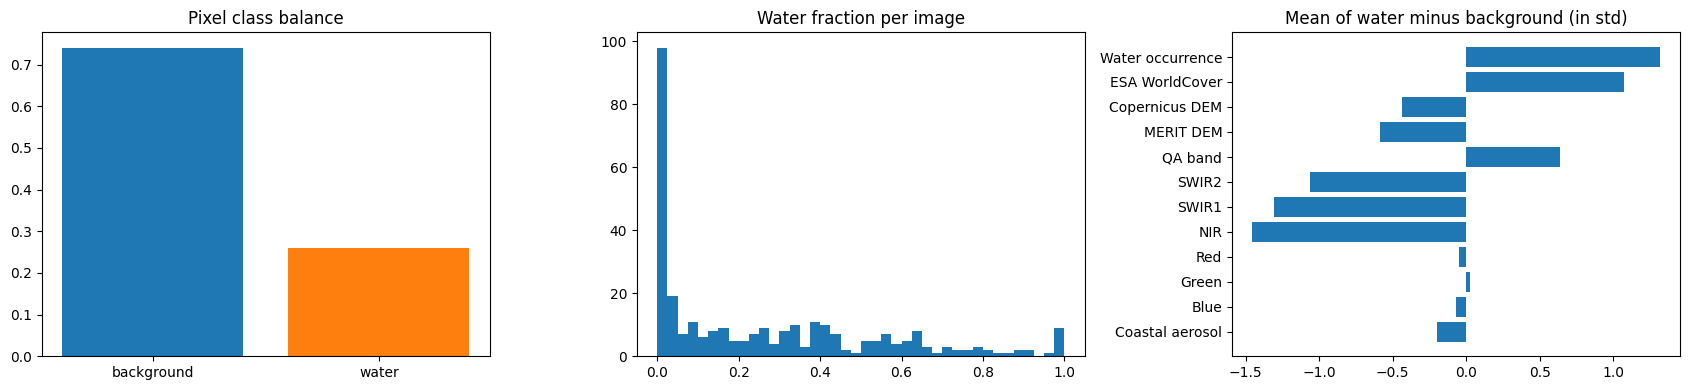

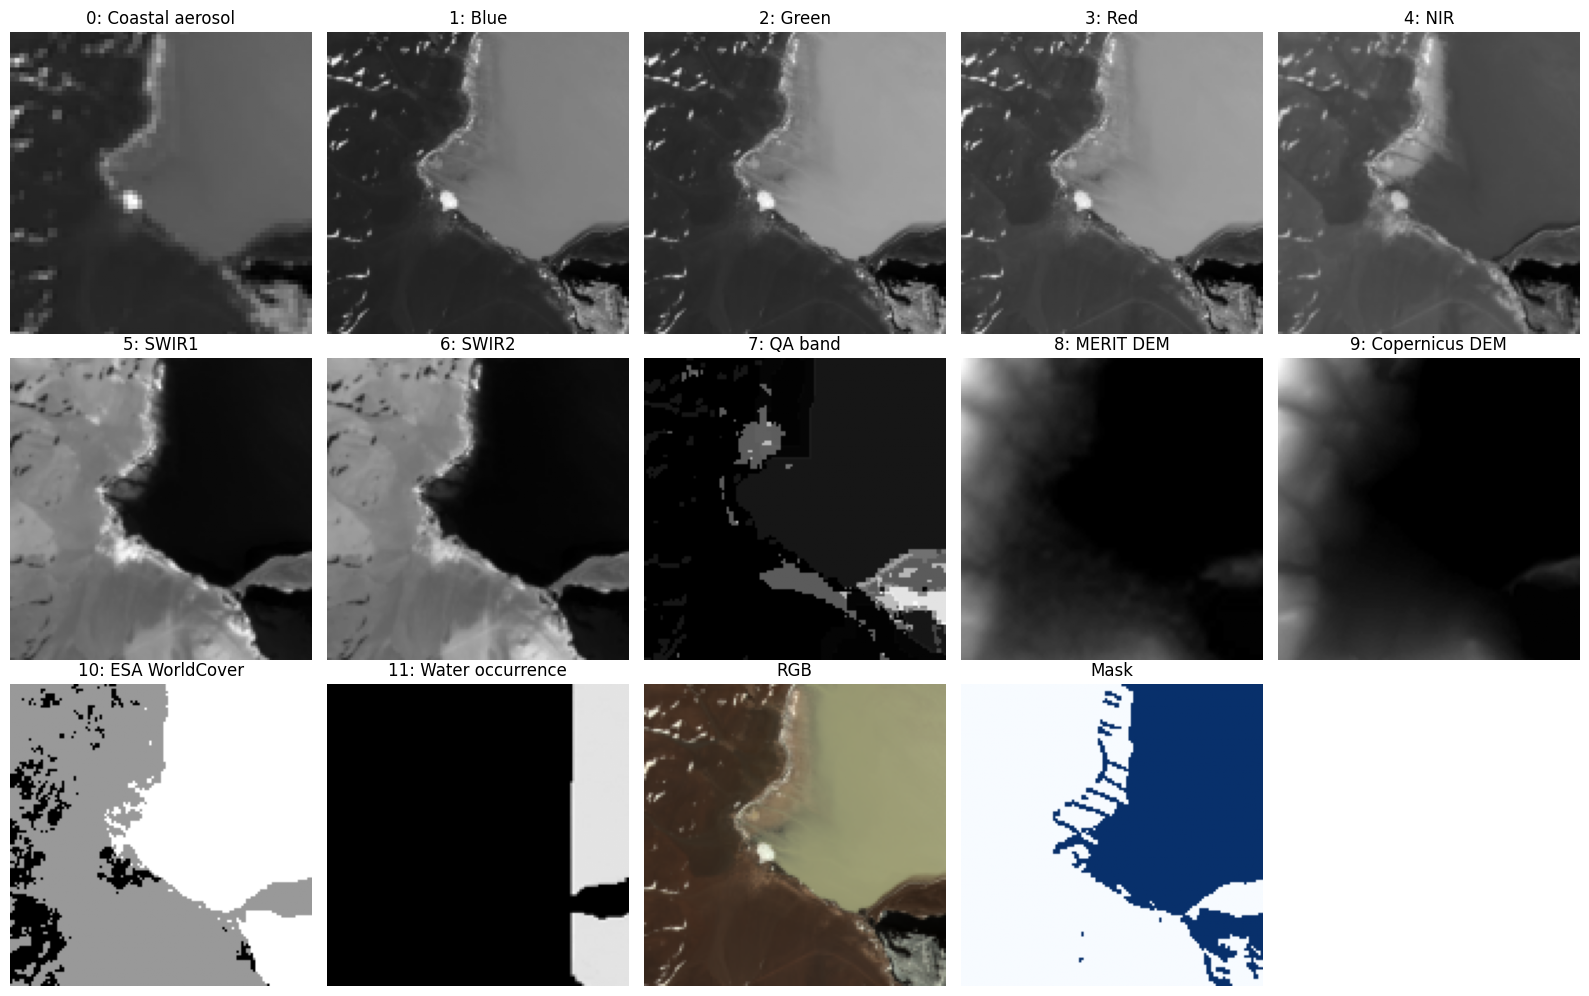

In [3]:
water_ratio = Y.mean()
per_image = Y.mean(axis=(1, 2))
print(f"water pixels {water_ratio:.2%} | images without water {(per_image == 0).mean():.2%}")
print(f"MERIT DEM minimum {X[:, 8].min():.0f} (no-data value) | water occurrence maximum {X[:, 11].max():.0f}")

separation = []
for c in range(C):
    v = np.clip(X[:, c], *np.percentile(X[:, c], [1, 99]))
    separation.append((v[Y > 0.5].mean() - v[Y < 0.5].mean()) / (v.std() + 1e-8))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].bar(["background", "water"], [1 - water_ratio, water_ratio], color=COLORS[:2])
axes[0].set_title("Pixel class balance")
axes[1].hist(per_image, bins=40)
axes[1].set_title("Water fraction per image")
axes[2].barh(BANDS, separation)
axes[2].set_title("Mean of water minus background (in std)")
plt.tight_layout()
plt.show()

k = int(np.argmin(np.abs(per_image - 0.4)))
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for c in range(C):
    axes.flat[c].imshow(X[k, c], cmap="gray")
    axes.flat[c].set_title(f"{c}: {BANDS[c]}")
rgb = X[k, [3, 2, 1]].transpose(1, 2, 0)
axes.flat[12].imshow((rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6))
axes.flat[12].set_title("RGB")
axes.flat[13].imshow(Y[k], cmap="Blues")
axes.flat[13].set_title("Mask")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Feature engineering

| Channel | Decision |
|---|---|
| Coastal aerosol, QA band, MERIT DEM | Drop: aerosol band correlated with Blue, bit flags, near-duplicate of Copernicus DEM with a -9999 no-data value |
| Blue, Green, Red, NIR, SWIR1, SWIR2 | Keep: water absorbs NIR and SWIR, Green is needed for the water indices |
| Copernicus DEM, Water occurrence | Keep: water lies in low flat areas, occurrence is the historical water frequency |
| ESA WorldCover | One-hot water and wetland channels instead of raw class codes |
| NDWI, MNDWI, NDVI, AWEI | Add: spectral water and vegetation indices |
| Slope, Relief | Add: flatness and height above the local 15 x 15 mean |

In [4]:
def norm_diff(a, b):
    return (a - b) / (a + b + 1e-6)

green, red, nir, swir1, swir2 = (X[:, i] for i in (2, 3, 4, 5, 6))
X[:, 12] = norm_diff(green, nir)
X[:, 13] = norm_diff(green, swir1)
X[:, 14] = norm_diff(nir, red)
X[:, 15] = 4 * (green - swir1) - (0.25 * nir + 2.75 * swir2)
del green, red, nir, swir1, swir2

dem = X[:, BANDS.index("Copernicus DEM")].copy()
gy, gx = np.gradient(dem, PIXEL_SIZE, axis=(1, 2))
X[:, NAMES.index("Slope")] = np.degrees(np.arctan(np.hypot(gx, gy)))
X[:, NAMES.index("Relief")] = dem - uniform_filter(dem, size=(1, 15, 15), mode="reflect")
del dem, gx, gy

LC = np.rint(X[:, BANDS.index("ESA WorldCover")]).astype(np.int16)
X[:, NAMES.index("WC water")] = LC == 80
X[:, NAMES.index("WC wetland")] = np.isin(LC, (90, 95))

## 5. Split and normalization

Two splits: 80% train and 20% validation. Every model uses its final-epoch weights, so no epoch is picked on the validation set. The validation set still guides the choice of techniques in Stage 2 and is the reported score, so the numbers are somewhat optimistic compared with a separate test set.

In [5]:
perm = np.random.permutation(N)
n_val = int(VAL_FRACTION * N)
val_idx = perm[:n_val]
train_idx = perm[n_val:]
print("train / validation:", len(train_idx), len(val_idx))

channel_stats = []
for c in range(X.shape[1]):
    if NAMES[c] in BINARY:
        channel_stats.append((0, 1, 0, 1))
        continue
    low, high = np.percentile(X[train_idx[:500], c], [1, 99])
    train_values = np.clip(X[train_idx, c], low, high)
    mean, std = train_values.mean(), train_values.std() + 1e-8
    X[:, c] = (np.clip(X[:, c], low, high) - mean) / std
    channel_stats.append((low, high, mean, std))

pd.DataFrame(channel_stats, index=NAMES, columns=["low", "high", "mean", "std"]).to_csv("normalization_stats.csv")

gt_val = Y[val_idx] > 0.5

train / validation: 245 61


## 6. Channel importance

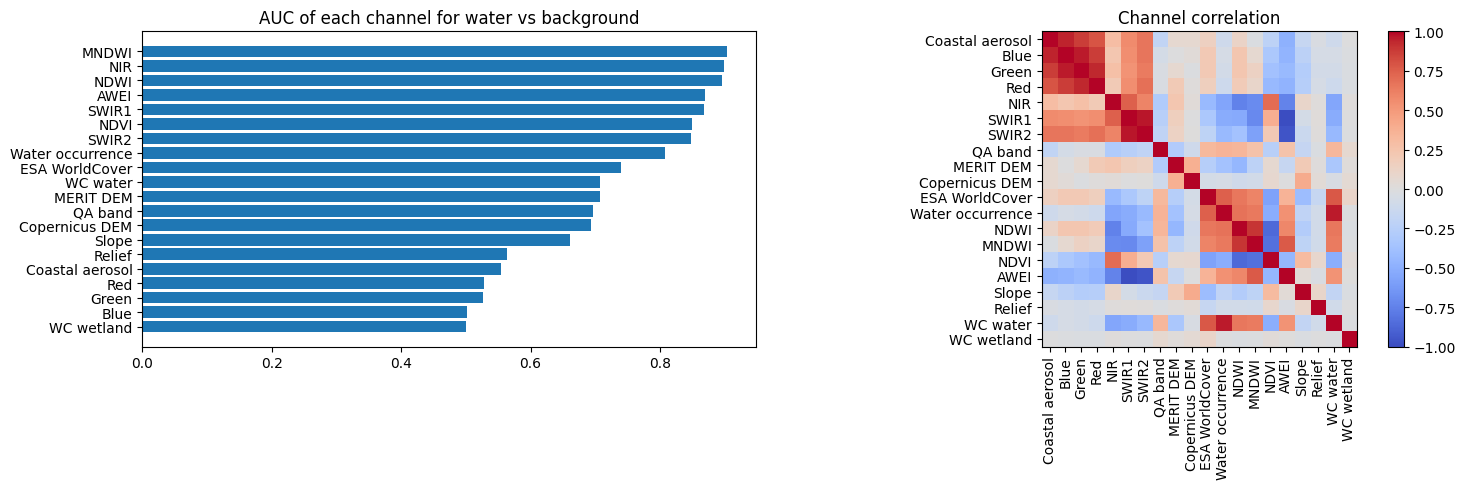

In [6]:
rng = np.random.default_rng(0)
sample_images = rng.choice(train_idx, size=min(300, len(train_idx)), replace=False)
pixel_ids = rng.integers(0, H * W, size=(len(sample_images), 400))
xs = np.concatenate([X[i].reshape(len(NAMES), -1)[:, p] for i, p in zip(sample_images, pixel_ids)], axis=1).T
ys = np.concatenate([Y[i].reshape(-1)[p] for i, p in zip(sample_images, pixel_ids)])

auc = np.array([max(a, 1 - a) for a in (roc_auc_score(ys, xs[:, c]) for c in range(len(NAMES)))])
order = np.argsort(auc)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh([NAMES[i] for i in order], auc[order])
axes[0].set_title("AUC of each channel for water vs background")
im = axes[1].imshow(np.corrcoef(xs.T), cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(NAMES)))
axes[1].set_xticklabels(NAMES, rotation=90)
axes[1].set_yticks(range(len(NAMES)))
axes[1].set_yticklabels(NAMES)
axes[1].set_title("Channel correlation")
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()

def idx(names):
    return [NAMES.index(n) for n in names]

core = ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"] + INDICES
FEATURE_SETS = {
    "all_12": list(range(12)),
    "plus_terrain_landcover": idx(core + ["Copernicus DEM", "Slope", "Relief", "Water occurrence", "WC water", "WC wetland"]),
}

## 7. Pretrained encoder and first-layer adaptation

ResNet encoders (ResNet34 here, ResNet50 as an upgrade) are pretrained on 3-channel ImageNet photos, so their low-level edge and texture filters transfer but the first convolution expects 3 channels. Two ways to adapt it to N channels:

- **average:** the three RGB filters are averaged, repeated on all N channels and scaled by 3 / N
- **zero-init:** the RGB filters go to the Red, Green and Blue channels and all other channels start at zero, so the network starts as the pretrained RGB model

In [7]:
def find_first_conv(model):
    for name, module in model.encoder.named_modules():
        if isinstance(module, nn.Conv2d) and module.in_channels == 3:
            return name, module
    raise RuntimeError("no 3-channel input convolution found")


def adapt_first_conv(model, in_channels, strategy, rgb_positions):
    name, conv = find_first_conv(model)
    w = conv.weight.data
    if strategy == "average":
        new_w = w.mean(dim=1, keepdim=True).repeat(1, in_channels, 1, 1) * (3.0 / in_channels)
    else:
        new_w = torch.zeros(w.shape[0], in_channels, *w.shape[2:], dtype=w.dtype)
        for src, dst in enumerate(rgb_positions):
            new_w[:, dst] = w[:, src]
    new_conv = copy.deepcopy(conv)
    new_conv.in_channels = in_channels
    new_conv.weight = nn.Parameter(new_w.clone())
    parent = model.encoder
    parts = name.split(".")
    for p in parts[:-1]:
        parent = getattr(parent, p)
    setattr(parent, parts[-1], new_conv)


class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=4, identity_init=True):
        super().__init__()
        hidden = max(channels // reduction, 2)
        self.fc = nn.Sequential(nn.Linear(channels, hidden), nn.ReLU(), nn.Linear(hidden, channels), nn.Sigmoid())
        if identity_init:
            nn.init.zeros_(self.fc[2].weight)
            nn.init.constant_(self.fc[2].bias, 3.0)

    def forward(self, x):
        return x * self.fc(x.mean(dim=(2, 3)))[:, :, None, None]


class WithAttention(nn.Module):
    def __init__(self, net, channels):
        super().__init__()
        self.attn, self.net = ChannelAttention(channels), net

    @property
    def encoder(self):
        return self.net.encoder

    def forward(self, x):
        return self.net(self.attn(x))


class Upscaled(nn.Module):
    def __init__(self, net, scale):
        super().__init__()
        self.net, self.scale = net, scale

    @property
    def encoder(self):
        return self.net.encoder

    def forward(self, x):
        return F.avg_pool2d(self.net(F.interpolate(x, scale_factor=self.scale, mode="bilinear", align_corners=False)), self.scale)


def build_model(cfg, channels, recipe):
    try:
        net = smp.Unet(encoder_name=cfg["encoder"], encoder_weights="imagenet", in_channels=3, classes=1)
    except Exception as e:
        raise RuntimeError("Could not download ImageNet weights. Turn internet on and run again.") from e
    rgb = [channels.index(NAMES.index(n)) for n in ("Red", "Green", "Blue")]
    adapt_first_conv(net, len(channels), cfg["strategy"], rgb)
    if recipe["scale"] > 1:
        net = Upscaled(net, recipe["scale"])
    return WithAttention(net, len(channels)) if recipe["attention"] else net


for strategy in ("average", "zero"):
    cfg = {"encoder": "resnet34", "strategy": strategy}
    m = build_model(cfg, FEATURE_SETS["all_12"], LEAN)
    first = next(mod for mod in m.encoder.modules() if isinstance(mod, nn.Conv2d))
    print(f"{strategy}: first conv {tuple(first.weight.shape)} | output {tuple(m(torch.randn(2, 12, H, W)).shape)} | {sum(p.numel() for p in m.parameters()) / 1e6:.1f} M parameters")
del m

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

average: first conv (64, 12, 7, 7) | output (2, 1, 128, 128) | 24.5 M parameters
zero: first conv (64, 12, 7, 7) | output (2, 1, 128, 128) | 24.5 M parameters


## 8. Training utilities

In [8]:
def bce_dice(logits, target):
    bce = F.binary_cross_entropy_with_logits(logits, target)
    prob = torch.sigmoid(logits)
    inter = (prob * target).sum(dim=(1, 2, 3))
    return bce + 1 - ((2 * inter + 1) / (prob.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3)) + 1)).mean()


def bce_tversky(logits, target, alpha=0.3, beta=0.7):
    bce = F.binary_cross_entropy_with_logits(logits, target)
    prob = torch.sigmoid(logits)
    tp = (prob * target).sum(dim=(1, 2, 3))
    fp = (prob * (1 - target)).sum(dim=(1, 2, 3))
    fn = ((1 - prob) * target).sum(dim=(1, 2, 3))
    return bce + 1 - ((tp + 1) / (tp + alpha * fp + beta * fn + 1)).mean()


LOSSES = {"dice": bce_dice, "tversky": bce_tversky}


class EMA:
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay

    @torch.no_grad()
    def update(self, model, step):
        d = min(self.decay, (1 + step) / (10 + step))
        for e, p in zip(self.module.parameters(), model.parameters()):
            e.lerp_(p, 1 - d)
        for e, b in zip(self.module.buffers(), model.buffers()):
            e.copy_(b)


class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.block(x)


class ScratchUNet(nn.Module):
    def __init__(self, in_channels, base=32):
        super().__init__()
        b = base
        self.attn = ChannelAttention(in_channels, identity_init=False)
        self.enc1, self.enc2 = DoubleConv(in_channels, b), DoubleConv(b, 2 * b)
        self.enc3, self.enc4 = DoubleConv(2 * b, 4 * b), DoubleConv(4 * b, 8 * b)
        self.bottleneck = DoubleConv(8 * b, 16 * b)
        self.pool = nn.MaxPool2d(2)
        self.up4, self.dec4 = nn.ConvTranspose2d(16 * b, 8 * b, 2, stride=2), DoubleConv(16 * b, 8 * b)
        self.up3, self.dec3 = nn.ConvTranspose2d(8 * b, 4 * b, 2, stride=2), DoubleConv(8 * b, 4 * b)
        self.up2, self.dec2 = nn.ConvTranspose2d(4 * b, 2 * b, 2, stride=2), DoubleConv(4 * b, 2 * b)
        self.up1, self.dec1 = nn.ConvTranspose2d(2 * b, b, 2, stride=2), DoubleConv(2 * b, b)
        self.head = nn.Conv2d(b, 1, 1)

    def forward(self, x):
        e1 = self.enc1(self.attn(x))
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        x = self.bottleneck(self.pool(e4))
        x = self.dec4(torch.cat([self.up4(x), e4], dim=1))
        x = self.dec3(torch.cat([self.up3(x), e3], dim=1))
        x = self.dec2(torch.cat([self.up2(x), e2], dim=1))
        x = self.dec1(torch.cat([self.up1(x), e1], dim=1))
        return self.head(x)


def make_loader(indices, channels, shuffle):
    x = torch.from_numpy(X[np.ix_(indices, channels)])
    y = torch.from_numpy(Y[indices]).unsqueeze(1)
    return DataLoader(TensorDataset(x, y), batch_size=BATCH_SIZE, shuffle=shuffle)


@torch.no_grad()
def predict_tensor(model, x):
    model.eval()
    return torch.cat([torch.sigmoid(model(b.to(device))).cpu() for b in x.split(BATCH_SIZE)]).squeeze(1).numpy()


def predict_proba(model, indices, channels):
    return predict_tensor(model, torch.from_numpy(X[np.ix_(indices, channels)]))


def scores(tp, fp, fn):
    precision, recall = tp / (tp + fp + 1e-9), tp / (tp + fn + 1e-9)
    return {"iou": tp / (tp + fp + fn + 1e-9), "precision": precision, "recall": recall,
            "f1": 2 * precision * recall / (precision + recall + 1e-9)}


def metrics(prob, gt, threshold=0.5):
    pred = prob > threshold
    return scores((pred & gt).sum(), (pred & ~gt).sum(), (~pred & gt).sum())


@torch.no_grad()
def val_pass(model, loader, loss_fn):
    model.eval()
    tp = fp = fn = tn = loss = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss += loss_fn(logits, y).item() * len(x)
        pred, gt = logits > 0, y > 0.5
        tp += (pred & gt).sum().item()
        fp += (pred & ~gt).sum().item()
        fn += (~pred & gt).sum().item()
        tn += (~pred & ~gt).sum().item()
    s = scores(tp, fp, fn)
    return {"val_loss": loss / len(loader.dataset), "val_acc": (tp + tn) / (tp + fp + fn + tn), "val_iou": s["iou"], "val_f1": s["f1"]}


def train(cfg, recipe, tag, seed=SEED):
    is_scratch = cfg["encoder"] == "scratch"
    hp = SCRATCH_HP if is_scratch else PRETRAINED_HP
    channels = FEATURE_SETS[cfg["feature_set"]]
    train_loader, val_loader = make_loader(train_idx, channels, True), make_loader(val_idx, channels, False)
    random.seed(seed)
    torch.manual_seed(seed)
    model = (ScratchUNet(len(channels)) if is_scratch else build_model(cfg, channels, recipe)).to(device)
    ema = EMA(model, EMA_DECAY) if recipe["ema"] else None
    eval_model = ema.module if ema else model
    loss_fn = LOSSES[recipe["loss"]]
    anc = [j for j, c in enumerate(channels) if NAMES[c] in ANCILLARY]

    if hasattr(model, "encoder"):
        enc = list(model.encoder.parameters())
        enc_ids = {id(p) for p in enc}
        groups = [{"params": enc, "lr": hp["lr_enc"]}, {"params": [p for p in model.parameters() if id(p) not in enc_ids], "lr": hp["lr_dec"]}]
    else:
        groups = [{"params": list(model.parameters()), "lr": hp["lr_dec"]}]
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-4)
    warm, epochs = hp["warm"], hp["epochs"]
    cosine = lambda e: 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * (e - warm) / (epochs - warm)))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda e: (e + 1) / warm if e < warm else cosine(e))

    history, step = [], 0
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = tp = fp = fn = tn = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            if random.random() < 0.5:
                x, y = x.flip(3), y.flip(3)
            if random.random() < 0.5:
                x, y = x.flip(2), y.flip(2)
            if hp["rotate"]:
                k = random.randint(0, 3)
                x, y = torch.rot90(x, k, (2, 3)), torch.rot90(y, k, (2, 3))
            if hp["anc_drop"]:
                drop = torch.rand(len(x), 1, 1, 1, device=x.device) < hp["anc_drop"]
                x[:, anc] = x[:, anc] * (~drop)
            optimizer.zero_grad()
            logits = model(x)
            loss = loss_fn(logits, y)
            loss.backward()
            optimizer.step()
            if ema:
                ema.update(model, step)
            step += 1
            loss_sum += loss.item() * len(x)
            pred, gt = logits > 0, y > 0.5
            tp += (pred & gt).sum().item()
            fp += (pred & ~gt).sum().item()
            fn += (~pred & gt).sum().item()
            tn += (~pred & ~gt).sum().item()
        scheduler.step()

        s = scores(tp, fp, fn)
        history.append({"epoch": epoch, "train_loss": loss_sum / len(train_idx), "train_acc": (tp + tn) / (tp + fp + fn + tn),
                        "train_iou": s["iou"], "train_f1": s["f1"], **val_pass(eval_model, val_loader, loss_fn)})
        if epoch == 1 or epoch % 25 == 0:
            h = history[-1]
            print(f"{tag} | epoch {epoch:3d} | train loss {h['train_loss']:.3f} acc {h['train_acc']:.3f} F1 {h['train_f1']:.3f} | "
                  f"val loss {h['val_loss']:.3f} acc {h['val_acc']:.3f} F1 {h['val_f1']:.3f} IoU {h['val_iou']:.3f}")

    run = {"model": eval_model, "channels": channels, "cfg": cfg, "recipe": recipe, "history": pd.DataFrame(history)}
    run["pv"] = predict_proba(eval_model, val_idx, channels)
    run["val"] = metrics(run["pv"], gt_val)
    print(f"{tag} | final epoch | val IoU {run['val']['iou']:.4f} | val F1 {run['val']['f1']:.4f}\n")
    return run


def plot_stage(runs, title, kept=None):
    labels = list(runs)
    pos = np.arange(len(labels))
    v = [runs[l]["val"]["iou"] for l in labels]
    fig, axes = plt.subplots(1, 2, figsize=(17, 0.5 * len(labels) + 4.5), gridspec_kw={"width_ratios": [1.2, 1]})

    for i, (label, r) in enumerate(runs.items()):
        axes[0].plot(r["history"].epoch, r["history"].val_iou, color=COLORS[i % 10], label=label)
    axes[0].axhline(scratch["val"]["iou"], ls="--", color="gray", label="Scratch U-Net")
    axes[0].set_ylim(bottom=0.65)
    axes[0].set_xlabel("epoch")
    axes[0].set_title("Validation IoU during training")
    axes[0].legend(fontsize=7, loc="lower right")

    bars = axes[1].barh(pos, v, 0.6, color=COLORS[0])
    for i, label in enumerate(labels):
        if kept is not None and not kept[label]:
            bars[i].set_hatch("//")
        axes[1].text(v[i], pos[i], f" {v[i]:.3f}", va="center", fontsize=8)
    axes[1].axvline(scratch["val"]["iou"], ls="--", color="gray")
    axes[1].set_yticks(pos)
    axes[1].set_yticklabels(labels, fontsize=9)
    axes[1].invert_yaxis()
    axes[1].set_xlim(min(v + [scratch["val"]["iou"]]) - 0.03, max(v) + 0.03)
    axes[1].set_title("Final validation IoU" + (" (hatched = dropped)" if kept is not None else ""))
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_trace(run, title):
    h = run["history"]
    panels = [("Loss", "train_loss", "val_loss"), (f"Pixel accuracy (always background: {1 - water_ratio:.2f})", "train_acc", "val_acc"),
              ("F1", "train_f1", "val_f1"), ("IoU", "train_iou", "val_iou")]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    for ax, (name, tr, va) in zip(axes.flat, panels):
        ax.plot(h.epoch, h[tr], label="train")
        ax.plot(h.epoch, h[va], "--", label="validation")
        ax.set_title(name)
        ax.set_xlabel("epoch")
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 9. Scratch U-Net baseline

The scratch U-Net from Week 1 (channel attention, EMA, BCE + Tversky, ancillary dropout) is retrained on this split, so both models are scored on the same validation images.

In [9]:
scratch = train({"encoder": "scratch", "feature_set": "plus_terrain_landcover"},
                dict(attention=False, ema=True, loss="tversky", scale=1), "scratch U-Net")

scratch U-Net | epoch   1 | train loss 1.129 acc 0.859 F1 0.726 | val loss 1.342 acc 0.919 F1 0.777 IoU 0.635
scratch U-Net | epoch  25 | train loss 0.667 acc 0.915 F1 0.839 | val loss 0.661 acc 0.934 F1 0.837 IoU 0.720
scratch U-Net | epoch  50 | train loss 0.538 acc 0.915 F1 0.843 | val loss 0.463 acc 0.937 F1 0.854 IoU 0.746
scratch U-Net | epoch  75 | train loss 0.470 acc 0.921 F1 0.855 | val loss 0.385 acc 0.933 F1 0.853 IoU 0.744
scratch U-Net | epoch 100 | train loss 0.454 acc 0.923 F1 0.861 | val loss 0.379 acc 0.941 F1 0.865 IoU 0.762
scratch U-Net | final epoch | val IoU 0.7618 | val F1 0.8648



## 10. Stage 1: input channels and first-layer adaptation

12ch average | epoch   1 | train loss 1.341 acc 0.634 F1 0.540 | val loss 2.015 acc 0.649 F1 0.541 IoU 0.371
12ch average | epoch  25 | train loss 0.603 acc 0.919 F1 0.855 | val loss 0.690 acc 0.926 F1 0.833 IoU 0.713
12ch average | epoch  50 | train loss 0.513 acc 0.923 F1 0.859 | val loss 0.433 acc 0.934 F1 0.856 IoU 0.748
12ch average | epoch  75 | train loss 0.372 acc 0.943 F1 0.895 | val loss 0.338 acc 0.948 F1 0.881 IoU 0.787
12ch average | epoch 100 | train loss 0.328 acc 0.950 F1 0.908 | val loss 0.316 acc 0.953 F1 0.890 IoU 0.802
12ch average | epoch 125 | train loss 0.303 acc 0.954 F1 0.916 | val loss 0.310 acc 0.956 F1 0.896 IoU 0.811
12ch average | epoch 150 | train loss 0.292 acc 0.956 F1 0.919 | val loss 0.303 acc 0.956 F1 0.896 IoU 0.812
12ch average | final epoch | val IoU 0.8124 | val F1 0.8965

12ch zero-init | epoch   1 | train loss 1.365 acc 0.613 F1 0.510 | val loss 1.478 acc 0.613 F1 0.509 IoU 0.341
12ch zero-init | epoch  25 | train loss 0.591 acc 0.922 F1 0.858 

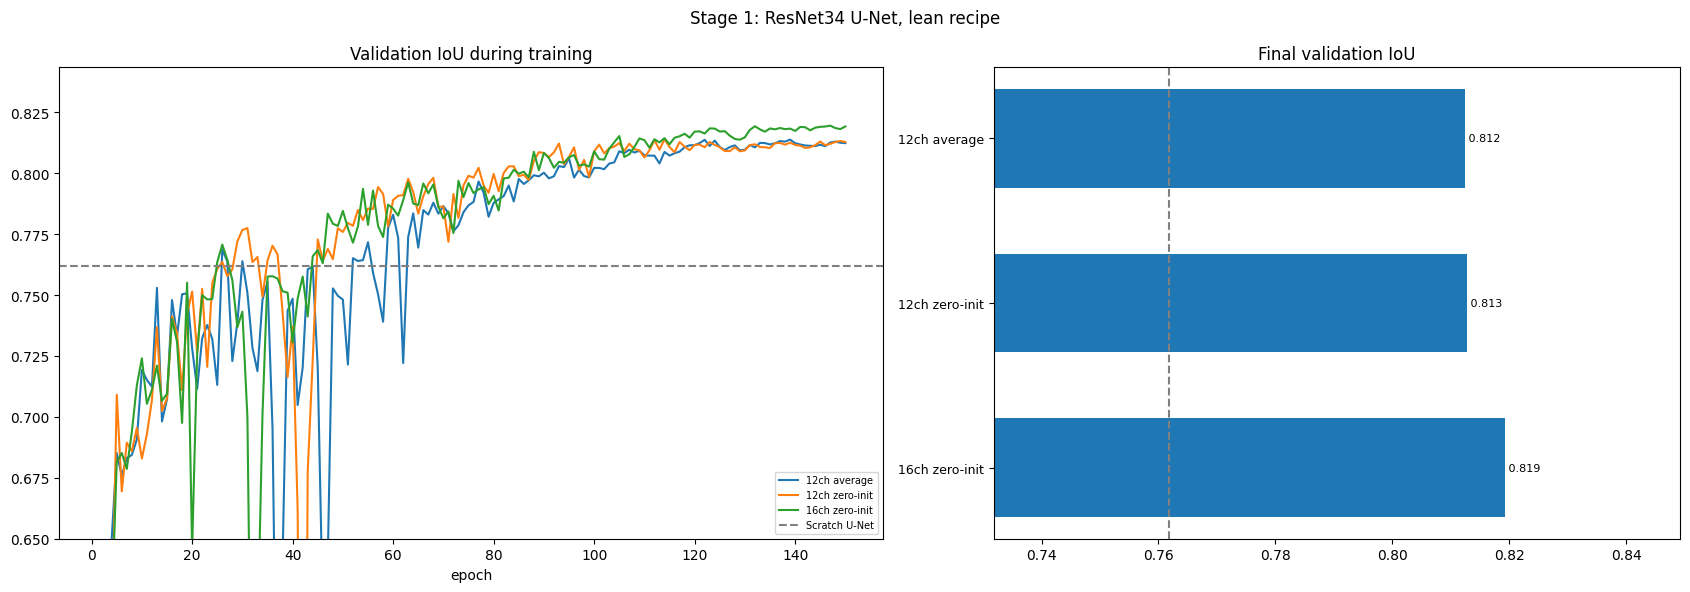

best input: 16ch zero-init


In [10]:
stage1 = {}
for inp in INPUTS:
    stage1[inp["name"]] = train({"encoder": "resnet34", **inp}, LEAN, inp["name"])

plot_stage(stage1, "Stage 1: ResNet34 U-Net, lean recipe")
base_label = max(stage1, key=lambda k: stage1[k]["val"]["iou"])
base = stage1[base_label]
print("best input:", base_label)

## 11. Stage 2: recipe build-up

Starting from the best Stage 1 model (BCE + Dice loss), each step adds one technique on top of the current best model and is kept only if validation IoU improves. Every run trains for a fixed number of epochs with a cosine schedule (no early stopping).

+ Tversky loss | epoch   1 | train loss 1.334 acc 0.618 F1 0.515 | val loss 1.436 acc 0.613 F1 0.512 IoU 0.344
+ Tversky loss | epoch  25 | train loss 0.498 acc 0.913 F1 0.849 | val loss 0.390 acc 0.937 F1 0.862 IoU 0.757
+ Tversky loss | epoch  50 | train loss 0.440 acc 0.929 F1 0.874 | val loss 0.366 acc 0.946 F1 0.875 IoU 0.778
+ Tversky loss | epoch  75 | train loss 0.331 acc 0.946 F1 0.902 | val loss 0.303 acc 0.954 F1 0.894 IoU 0.809
+ Tversky loss | epoch 100 | train loss 0.294 acc 0.953 F1 0.915 | val loss 0.280 acc 0.957 F1 0.901 IoU 0.820
+ Tversky loss | epoch 125 | train loss 0.275 acc 0.957 F1 0.922 | val loss 0.278 acc 0.959 F1 0.904 IoU 0.825
+ Tversky loss | epoch 150 | train loss 0.263 acc 0.959 F1 0.926 | val loss 0.270 acc 0.959 F1 0.906 IoU 0.828
+ Tversky loss | final epoch | val IoU 0.8277 | val F1 0.9057

+ attention + EMA | epoch   1 | train loss 1.321 acc 0.635 F1 0.533 | val loss 1.540 acc 0.667 F1 0.552 IoU 0.381
+ attention + EMA | epoch  25 | train loss 0.4

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

+ ResNet50 encoder | epoch   1 | train loss 1.290 acc 0.588 F1 0.542 | val loss 1.614 acc 0.531 F1 0.480 IoU 0.315
+ ResNet50 encoder | epoch  25 | train loss 0.449 acc 0.931 F1 0.875 | val loss 0.400 acc 0.950 F1 0.885 IoU 0.794
+ ResNet50 encoder | epoch  50 | train loss 0.343 acc 0.943 F1 0.898 | val loss 0.307 acc 0.952 F1 0.893 IoU 0.807
+ ResNet50 encoder | epoch  75 | train loss 0.301 acc 0.953 F1 0.913 | val loss 0.293 acc 0.958 F1 0.904 IoU 0.824
+ ResNet50 encoder | epoch 100 | train loss 0.251 acc 0.959 F1 0.926 | val loss 0.259 acc 0.960 F1 0.910 IoU 0.835
+ ResNet50 encoder | epoch 125 | train loss 0.230 acc 0.964 F1 0.935 | val loss 0.258 acc 0.961 F1 0.911 IoU 0.837
+ ResNet50 encoder | epoch 150 | train loss 0.223 acc 0.966 F1 0.938 | val loss 0.257 acc 0.962 F1 0.912 IoU 0.839
+ ResNet50 encoder | final epoch | val IoU 0.8385 | val F1 0.9122

kept: ['baseline (16ch zero-init)', '+ Tversky loss', '+ attention + EMA', '+ 2x input upscaling', '+ ResNet50 encoder']
dropped

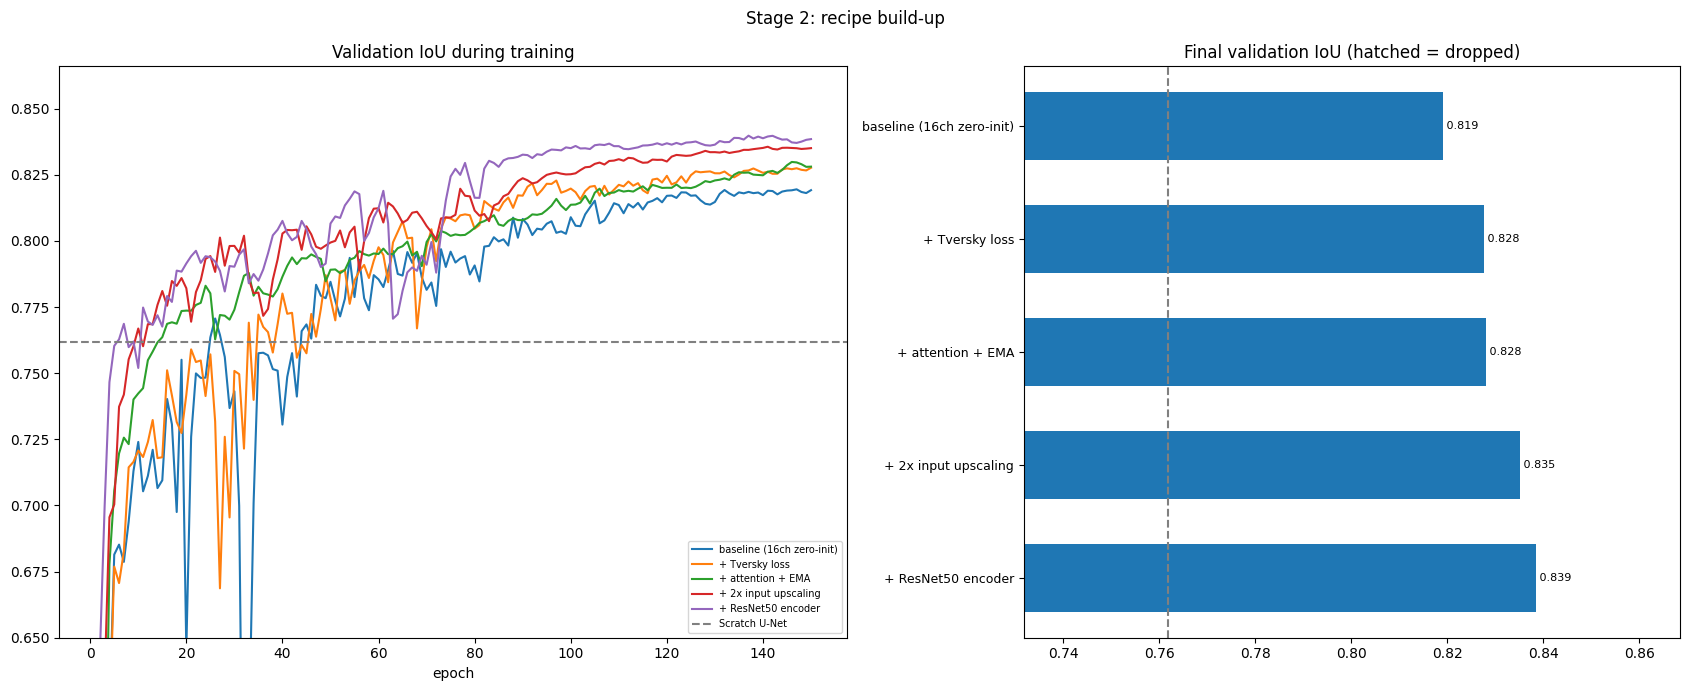

In [11]:
stage2 = {f"baseline ({base_label})": base}
kept = {f"baseline ({base_label})": True}
best = base
for label, cfg_update, recipe_update in STEPS:
    run = train({**best["cfg"], **cfg_update}, {**best["recipe"], **recipe_update}, label)
    stage2[label] = run
    kept[label] = run["val"]["iou"] > best["val"]["iou"]
    if kept[label]:
        best = run

final = best
print("kept:", [l for l in kept if kept[l]])
print("dropped:", [l for l in kept if not kept[l]])
plot_stage(stage2, "Stage 2: recipe build-up", kept)

## 12. Final model: training trace

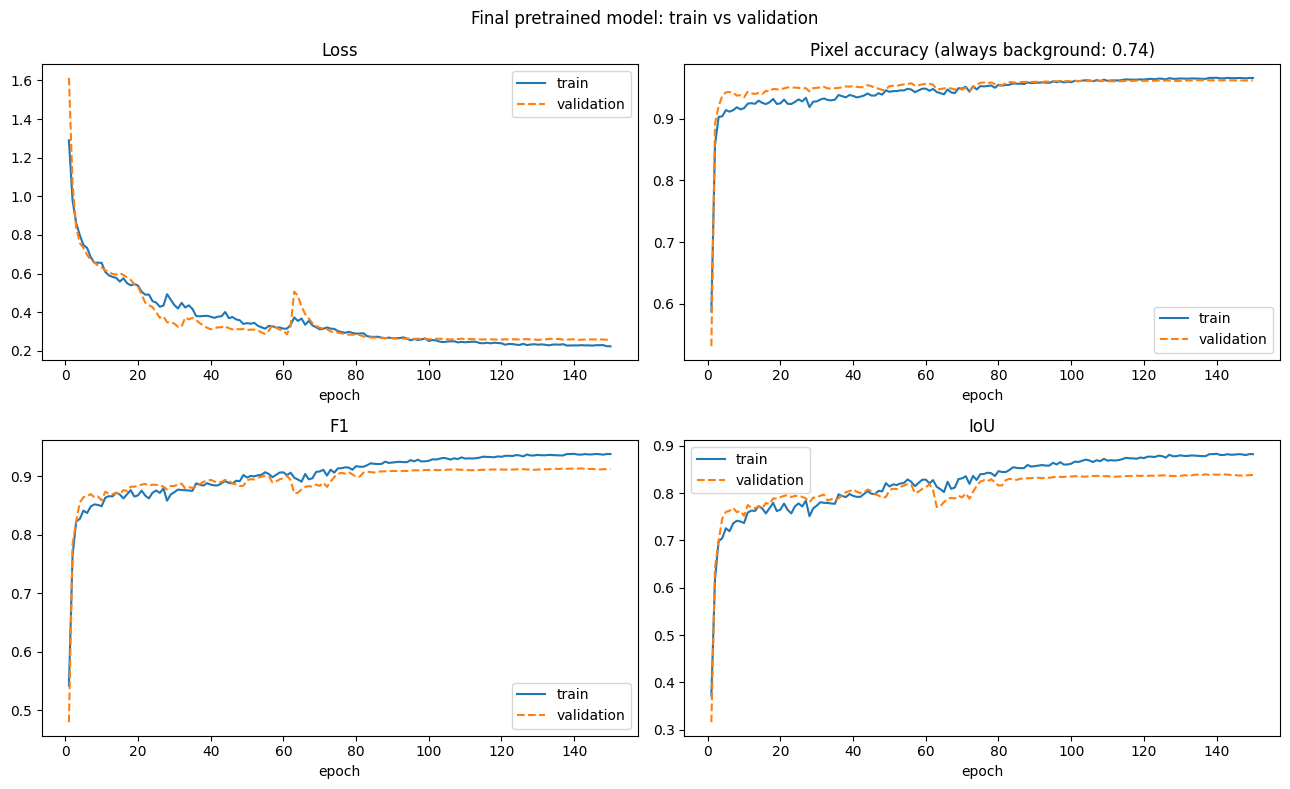

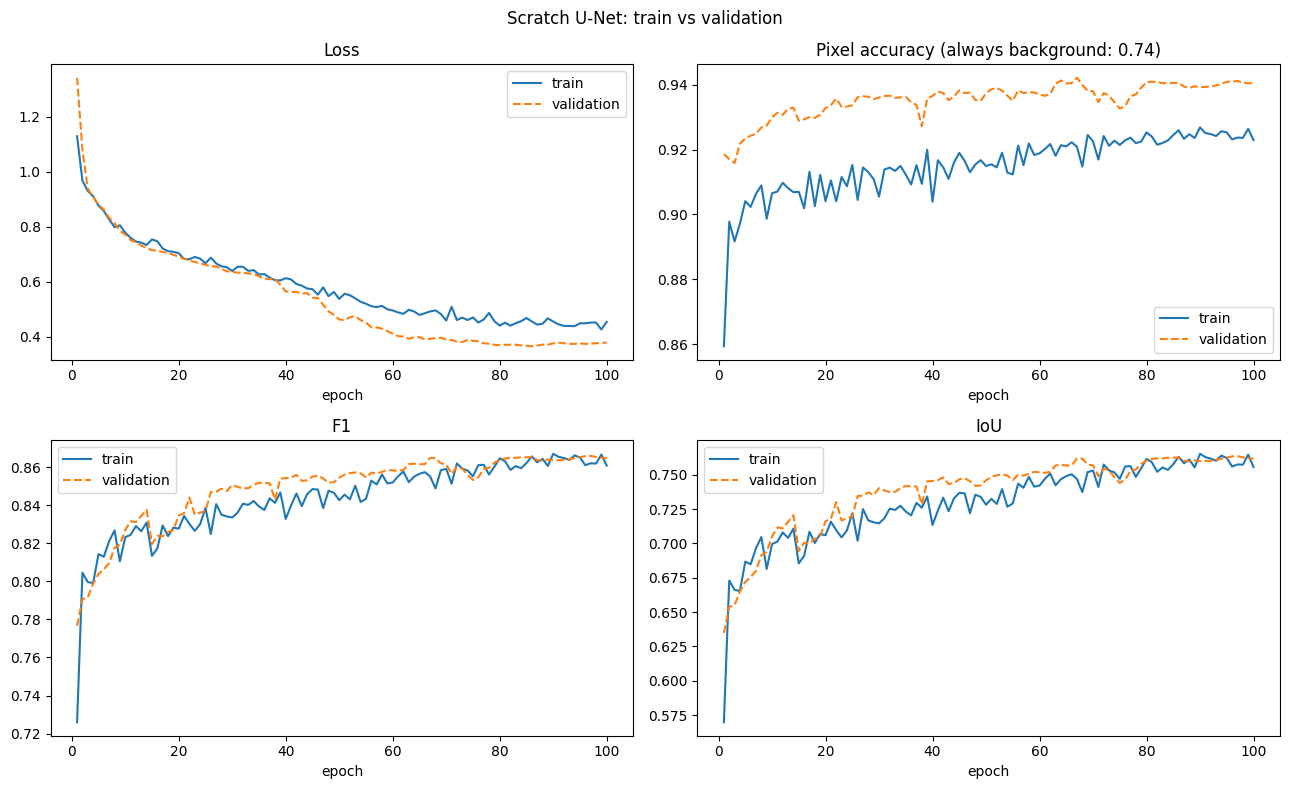

In [12]:
plot_trace(final, "Final pretrained model: train vs validation")
plot_trace(scratch, "Scratch U-Net: train vs validation")

## 13. Test-time augmentation and seed stability

In [13]:
def predict_tta(model, indices, channels):
    x = torch.from_numpy(X[np.ix_(indices, channels)])
    total = 0
    for flip in (False, True):
        for k in range(4):
            t = torch.rot90(x.flip(3) if flip else x, k, (2, 3))
            p = torch.rot90(torch.from_numpy(predict_tensor(model, t)), -k, (1, 2))
            total = total + (p.flip(2) if flip else p)
    return (total / 8).numpy()


final_tta = metrics(predict_tta(final["model"], val_idx, final["channels"]), gt_val)

seed_runs = [final] + [train(final["cfg"], final["recipe"], f"seed {sd}", sd) for sd in SEEDS_EXTRA]
v = [r["val"]["iou"] for r in seed_runs]
print(f"validation IoU over {len(seed_runs)} seeds: {np.mean(v):.4f} ± {np.std(v):.4f}")

seed 43 | epoch   1 | train loss 1.235 acc 0.734 F1 0.592 | val loss 1.410 acc 0.752 F1 0.620 IoU 0.449
seed 43 | epoch  25 | train loss 0.430 acc 0.931 F1 0.874 | val loss 0.358 acc 0.946 F1 0.879 IoU 0.785
seed 43 | epoch  50 | train loss 0.341 acc 0.943 F1 0.899 | val loss 0.295 acc 0.950 F1 0.890 IoU 0.802
seed 43 | epoch  75 | train loss 0.265 acc 0.958 F1 0.924 | val loss 0.270 acc 0.959 F1 0.907 IoU 0.830
seed 43 | epoch 100 | train loss 0.251 acc 0.960 F1 0.928 | val loss 0.291 acc 0.960 F1 0.906 IoU 0.828
seed 43 | epoch 125 | train loss 0.219 acc 0.966 F1 0.938 | val loss 0.269 acc 0.960 F1 0.908 IoU 0.831
seed 43 | epoch 150 | train loss 0.208 acc 0.969 F1 0.944 | val loss 0.274 acc 0.960 F1 0.908 IoU 0.832
seed 43 | final epoch | val IoU 0.8317 | val F1 0.9081

seed 44 | epoch   1 | train loss 1.228 acc 0.760 F1 0.577 | val loss 1.221 acc 0.883 F1 0.725 IoU 0.569
seed 44 | epoch  25 | train loss 0.433 acc 0.920 F1 0.860 | val loss 0.350 acc 0.943 F1 0.872 IoU 0.773
seed 44 

## 14. Comparison with the scratch U-Net

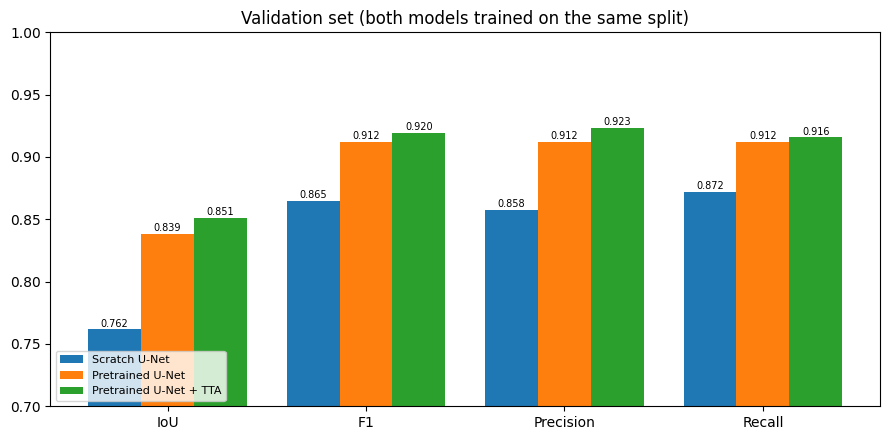

validation IoU 0.8385 vs scratch U-Net 0.7618 (delta +0.0767), higher than scratch U-Net: yes

| Model | Val IoU | Val F1 | Val Precision | Val Recall |
|---|---|---|---|---|
| Scratch U-Net | 0.7618 | 0.8648 | 0.8578 | 0.8719 |
| Pretrained U-Net | 0.8385 | 0.9122 | 0.9121 | 0.9123 |
| Pretrained U-Net + TTA | 0.8512 | 0.9196 | 0.9234 | 0.9159 |


In [14]:
models = {"Scratch U-Net": scratch["val"], "Pretrained U-Net": final["val"], "Pretrained U-Net + TTA": final_tta}
keys = ["iou", "f1", "precision", "recall"]

fig, ax = plt.subplots(figsize=(9, 4.5))
width = 0.8 / len(models)
for i, (name, m) in enumerate(models.items()):
    vals = [m[k] for k in keys]
    bars = ax.bar(np.arange(4) + i * width - 0.4 + width / 2, vals, width, label=name, color=COLORS[i])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.002, f"{v:.3f}", ha="center", fontsize=7)
ax.set_xticks(range(4))
ax.set_xticklabels(["IoU", "F1", "Precision", "Recall"])
ax.set_ylim(0.7, 1.0)
ax.set_title("Validation set (both models trained on the same split)")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

delta = final["val"]["iou"] - scratch["val"]["iou"]
print(f"validation IoU {final['val']['iou']:.4f} vs scratch U-Net {scratch['val']['iou']:.4f} (delta {delta:+.4f}), higher than scratch U-Net: {'yes' if delta > 0 else 'no'}\n")

print("| Model | Val IoU | Val F1 | Val Precision | Val Recall |\n|---|---|---|---|---|")
for name, m in models.items():
    print(f"| {name} | " + " | ".join(f"{m[k]:.4f}" for k in keys) + " |")

## 15. Analysis of the final model

  0%|          | 0/16 [00:00<?, ?it/s]

validation IoU 0.8385 | with all ancillary channels zeroed 0.7986


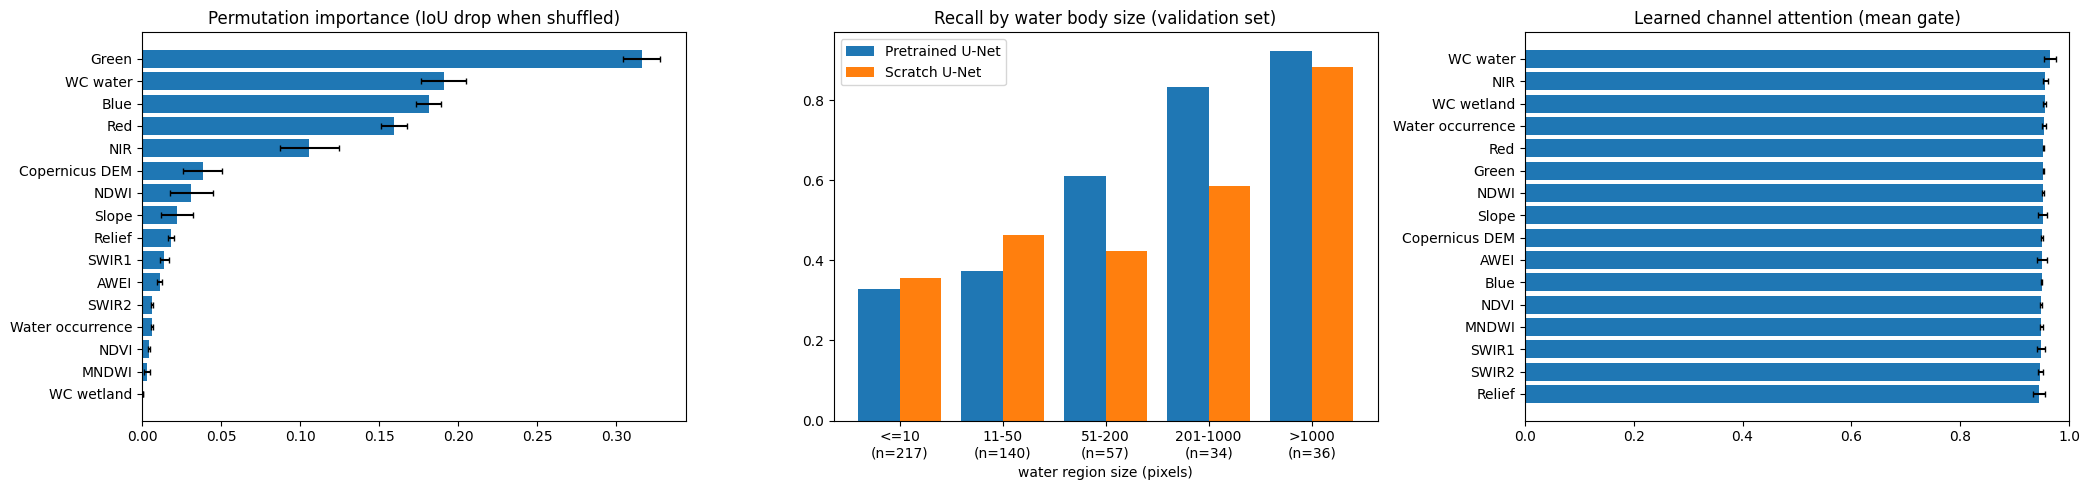

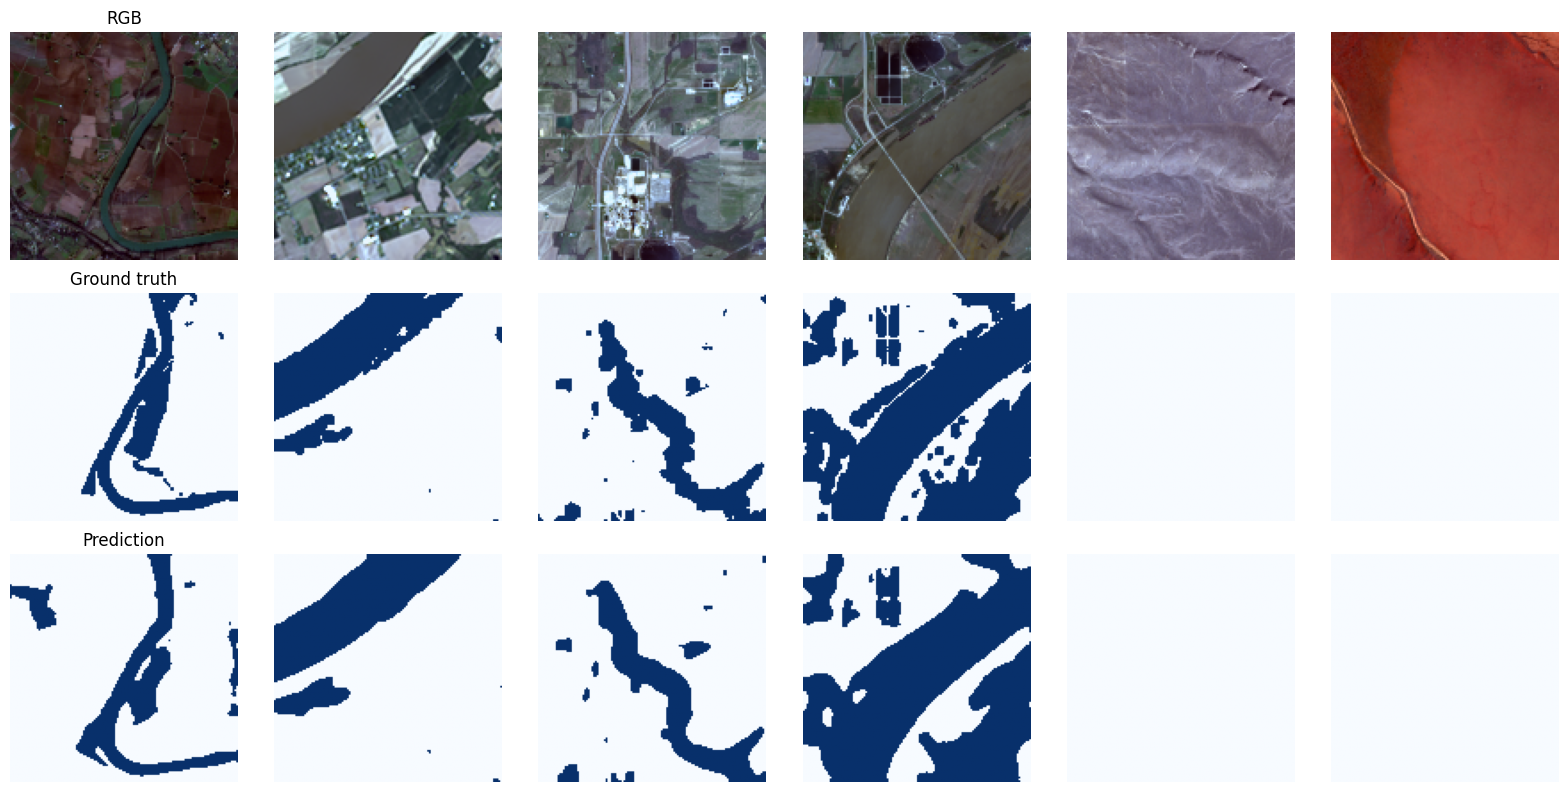

In [15]:
channels = final["channels"]
names = [NAMES[c] for c in channels]
x = torch.from_numpy(X[np.ix_(val_idx, channels)])

base_iou = metrics(predict_tensor(final["model"], x), gt_val)["iou"]
g = torch.Generator().manual_seed(0)
drops = np.zeros((len(channels), 3))
for j in tqdm(range(len(channels))):
    for r in range(3):
        xp = x.clone()
        xp[:, j] = x[torch.randperm(len(x), generator=g), j]
        drops[j, r] = base_iou - metrics(predict_tensor(final["model"], xp), gt_val)["iou"]

xz = x.clone()
xz[:, [j for j, c in enumerate(channels) if NAMES[c] in ANCILLARY]] = 0
print(f"validation IoU {base_iou:.4f} | with all ancillary channels zeroed {metrics(predict_tensor(final['model'], xz), gt_val)['iou']:.4f}")


def recall_by_size(prob):
    pred = prob > 0.5
    sizes, recalls = [], []
    for i in range(len(gt_val)):
        lab, n = cc_label(gt_val[i])
        for k in range(1, n + 1):
            region = lab == k
            sizes.append(int(region.sum()))
            recalls.append(pred[i][region].mean())
    ids = np.digitize(np.array(sizes), [10, 50, 200, 1000], right=True)
    recalls = np.array(recalls)
    return [recalls[ids == b].mean() if (ids == b).any() else 0 for b in range(5)], [int((ids == b).sum()) for b in range(5)]


rec_final, counts = recall_by_size(final["pv"])
rec_scratch, _ = recall_by_size(scratch["pv"])
size_labels = ["<=10", "11-50", "51-200", "201-1000", ">1000"]

n_panels = 3 if final["recipe"]["attention"] else 2
fig, axes = plt.subplots(1, n_panels, figsize=(7 * n_panels, 5))
order = np.argsort(drops.mean(1))
axes[0].barh([names[i] for i in order], drops.mean(1)[order], xerr=drops.std(1)[order], capsize=2)
axes[0].set_title("Permutation importance (IoU drop when shuffled)")

axes[1].bar(np.arange(5) - 0.2, rec_final, 0.4, label="Pretrained U-Net")
axes[1].bar(np.arange(5) + 0.2, rec_scratch, 0.4, label="Scratch U-Net")
axes[1].set_xticks(range(5))
axes[1].set_xticklabels([f"{l}\n(n={c})" for l, c in zip(size_labels, counts)])
axes[1].set_xlabel("water region size (pixels)")
axes[1].set_title("Recall by water body size (validation set)")
axes[1].legend()

if final["recipe"]["attention"]:
    with torch.no_grad():
        final["model"].eval()
        w = torch.cat([final["model"].attn.fc(b.to(device).mean(dim=(2, 3))).cpu() for b in x.split(BATCH_SIZE)]).numpy()
    order = np.argsort(w.mean(0))
    axes[2].barh([names[i] for i in order], w.mean(0)[order], xerr=w.std(0)[order], capsize=2)
    axes[2].set_xlim(0, 1)
    axes[2].set_title("Learned channel attention (mean gate)")
plt.tight_layout()
plt.show()

xb, yb = next(iter(make_loader(val_idx[:6], channels, False)))
pred = predict_tensor(final["model"], xb) > 0.5
fig, axes = plt.subplots(3, 6, figsize=(16, 8))
for j in range(len(xb)):
    rgb = X[val_idx[j], [3, 2, 1]].transpose(1, 2, 0)
    axes[0, j].imshow((rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6))
    axes[1, j].imshow(yb[j, 0], cmap="Blues")
    axes[2, j].imshow(pred[j], cmap="Blues")
for ax in axes.flat:
    ax.axis("off")
axes[0, 0].set_title("RGB")
axes[1, 0].set_title("Ground truth")
axes[2, 0].set_title("Prediction")
plt.tight_layout()
plt.show()

torch.save(final["model"].state_dict(), "best_pretrained_model_two_way.pt")
pd.concat({n: r["history"] for n, r in {"scratch U-Net": scratch, **stage1, **stage2}.items()}, names=["model"]).to_csv("training_histories_two_way.csv")

The pretrained encoder brings edge and texture filters that are useful from the first epoch, so water boundaries are learned from 245 training images far more easily than from random weights. It is also deeper, with residual connections that ease optimisation and a larger receptive field for separating shadows from water. Part of the gain also comes from training longer (150 against 100 epochs) and from rotation augmentation. Because the validation set both guides Stage 2 and reports the score, treat the numbers as optimistic and compare them mainly with the scratch U-Net trained on the same split.